# Pythonによる はじめての銀河形成シミュレーション
## 最小モデル：2つのPlummer銀河とテスト粒子

このNotebookでは、本書の最終到達点となる最小モデルを実装します。

- 2つの銀河を移動する **Plummerポテンシャル** で表します。
- 恒星円盤は **質量ゼロのテスト粒子** で表します。
- テスト粒子同士の重力は計算しません。
- 銀河中心は互いの重力で運動します。
- 時間積分には **4次Runge--Kutta法（RK4）** を使います。
- 円盤粒子の半径分布は、**台形則 → 累積分布関数 → 線形補間** で生成します。

標準モデルは、同じ質量をもつ2つの銀河による coplanar prograde--prograde encounter です。

## 1. 使用する単位と標準パラメータ

単位は

- 距離：kpc
- 時間：Gyr
- 質量：$M_\odot$

とします。

重力定数は、この単位系に変換して使います。

各銀河のPlummerポテンシャルは

$$
\Phi(r)=-\frac{GM}{\sqrt{r^2+a^2}}
$$

です。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

KM_S_TO_KPC_GYR = 1.0227121650537077
G = 4.30091e-6 * KM_S_TO_KPC_GYR**2

M1 = 1.0e11
M2 = 1.0e11
A1 = 3.0
A2 = 3.0
A_ORBIT = 3.0

RD1 = 3.0
RD2 = 3.0
RMAX1 = 15.0
RMAX2 = 15.0

N1 = 1000
N2 = 1000
SPIN_1 = +1
SPIN_2 = +1

R0 = 60.0
R_PERI = 8.0

DT = 0.001
T_END = 0.60
SNAPSHOT_TIMES = [0.00, 0.20, 0.27, 0.35, 0.50, 0.60]
RANDOM_SEED = 42

BLUE = "#0072B2"
VERMILLION = "#D55E00"
BLACK = "#000000"

print(f"G = {G:.6e} kpc^3 Msun^-1 Gyr^-2")

G = 4.498495e-06 kpc^3 Msun^-1 Gyr^-2


## 2. Plummerポテンシャルによる重力加速度

Plummerポテンシャルから得られる加速度は

$$
\boldsymbol a
=
-GM\frac{\boldsymbol r}
{(r^2+a^2)^{3/2}}
$$

です。

テスト粒子は2つの銀河から重力を受けます。一方、銀河中心同士の運動には、有限サイズを表すために同じ形のsoftened forceを使います。

In [2]:
def plummer_acceleration(pos, center, mass, a):
    dr = pos - center
    r2 = np.sum(dr * dr, axis=-1)
    return -G * mass * dr / (r2 + a * a)[..., None]**1.5

def center_accelerations(r1, r2):
    dr = r2 - r1
    r2_sep = np.dot(dr, dr)
    denom = (r2_sep + A_ORBIT**2)**1.5
    a1 = G * M2 * dr / denom
    a2 = -G * M1 * dr / denom
    return a1, a2

## 3. RK4で運動方程式を積分する

位置と速度をまとめて

$$
\boldsymbol y=(\boldsymbol r,\boldsymbol v)
$$

とすると、運動方程式は1階の連立常微分方程式

$$
\frac{d\boldsymbol y}{dt}=\boldsymbol f(\boldsymbol y,t)
$$

として扱えます。

ここでは古典的な4次Runge--Kutta法を使います。本書ではRK4を標準の時間積分法とし、leapfrog法などは別の代表的方法として紹介します。

In [3]:
def rhs(state):
    deriv = np.empty_like(state)
    deriv[:, 0:2] = state[:, 2:4]

    r1 = state[0, 0:2]
    r2 = state[1, 0:2]
    a1, a2 = center_accelerations(r1, r2)
    deriv[0, 2:4] = a1
    deriv[1, 2:4] = a2

    pos = state[2:, 0:2]
    acc = plummer_acceleration(pos, r1, M1, A1) + plummer_acceleration(pos, r2, M2, A2)
    deriv[2:, 2:4] = acc

    return deriv

def rk4_step(state, dt):
    k1 = rhs(state)
    k2 = rhs(state + 0.5 * dt * k1)
    k3 = rhs(state + 0.5 * dt * k2)
    k4 = rhs(state + dt * k3)
    return state + dt * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0

## 4. 指数円盤からテスト粒子を生成する

恒星円盤の面密度を

$$
\Sigma(R)\propto \exp(-R/R_d)
$$

とします。

半径 $R$ から $R+dR$ に入る粒子数は面積要素 $2\pi R\,dR$ を含むので、

$$
p(R)\,dR \propto R\exp(-R/R_d)\,dR
$$

です。

ここでは $p(R)$ を格子上で計算し、**台形則**で累積分布関数（CDF）を作ります。その後、乱数 $u\in[0,1]$ に対して **線形補間**を使ってCDFを逆変換します。

In [4]:
def sample_exponential_disk(n, rd, rmax, rng):
    r_grid = np.linspace(0.0, rmax, 4097)
    pdf = r_grid * np.exp(-r_grid / rd)

    cdf = np.zeros_like(r_grid)
    dr = np.diff(r_grid)
    cdf[1:] = np.cumsum(0.5 * (pdf[:-1] + pdf[1:]) * dr)
    cdf /= cdf[-1]

    u = rng.random(n)
    radius = np.interp(u, cdf, r_grid)
    phi = 2.0 * np.pi * rng.random(n)

    pos = np.column_stack((radius * np.cos(phi), radius * np.sin(phi)))
    return pos, radius, phi

def circular_speed_plummer(radius, mass, a):
    return np.sqrt(G * mass * radius**2 / (radius**2 + a**2)**1.5)

def make_disk(n, center, center_velocity, mass, a, rd, rmax, spin, rng):
    rel_pos, radius, phi = sample_exponential_disk(n, rd, rmax, rng)
    vc = circular_speed_plummer(radius, mass, a)
    tangent = np.column_stack((-np.sin(phi), np.cos(phi)))
    rel_vel = spin * vc[:, None] * tangent
    pos = center + rel_pos
    vel = center_velocity + rel_vel
    return pos, vel

### 円盤の初期分布を確認する

まず、相互作用させる前の指数円盤が意図した形に生成されているか確認します。

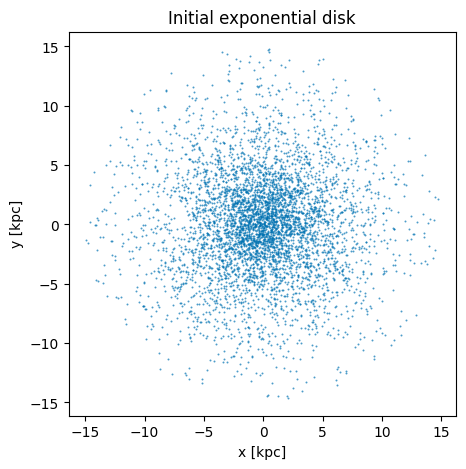

In [5]:
rng_test = np.random.default_rng(RANDOM_SEED)
pos_test, radius_test, _ = sample_exponential_disk(5000, RD1, RMAX1, rng_test)

fig, ax = plt.subplots(figsize=(5.0, 5.0))
ax.scatter(pos_test[:, 0], pos_test[:, 1], s=2.0, c=BLUE, alpha=0.7, linewidths=0)
ax.set_xlabel("x [kpc]")
ax.set_ylabel("y [kpc]")
ax.set_aspect("equal")
ax.set_title("Initial exponential disk")
plt.show()

## 5. 2つの銀河中心の初期軌道

標準モデルでは、相対運動に対して

$$
\Phi_{\rm rel}(r)
=
-\frac{G(M_1+M_2)}
{\sqrt{r^2+a_{\rm orb}^2}}
$$

という有効ポテンシャルを使います。

軌道エネルギーを0とした encounter を設定し、目標最近接距離を $r_{\rm p}=8$ kpc とします。この条件から初期の動径速度と接線速度を求めます。

In [6]:
def make_zero_energy_encounter(r0, rperi):
    mu = G * (M1 + M2)

    h2 = 2.0 * mu * rperi**2 / np.sqrt(rperi**2 + A_ORBIT**2)
    h = np.sqrt(h2)

    vrel2 = 2.0 * mu / np.sqrt(r0**2 + A_ORBIT**2)
    vt = h / r0
    vr = -np.sqrt(vrel2 - vt**2)

    separation = np.array([r0, 0.0])
    relative_velocity = np.array([vr, vt])

    mtot = M1 + M2
    r1 = -(M2 / mtot) * separation
    r2 = +(M1 / mtot) * separation
    v1 = -(M2 / mtot) * relative_velocity
    v2 = +(M1 / mtot) * relative_velocity

    return r1, r2, v1, v2

r1, r2, v1, v2 = make_zero_energy_encounter(R0, R_PERI)
vrel = v2 - v1

print(f"Initial separation = {np.linalg.norm(r2 - r1):.1f} kpc")
print(f"Relative radial velocity = {vrel[0] / KM_S_TO_KPC_GYR:.1f} km/s")
print(f"Relative tangential velocity = {vrel[1] / KM_S_TO_KPC_GYR:.1f} km/s")
print(f"Relative speed = {np.linalg.norm(vrel) / KM_S_TO_KPC_GYR:.1f} km/s")

Initial separation = 60.0 kpc
Relative radial velocity = -158.3 km/s
Relative tangential velocity = 59.8 km/s
Relative speed = 169.2 km/s


## 6. 初期状態を作る

`state` の各行は1個の粒子を表し、

```text
[x, y, vx, vy]
```

を保存します。

最初の2行が銀河中心、その後がテスト粒子です。

In [7]:
def make_initial_state():
    rng = np.random.default_rng(RANDOM_SEED)

    r1, r2, v1, v2 = make_zero_energy_encounter(R0, R_PERI)
    pos1, vel1 = make_disk(N1, r1, v1, M1, A1, RD1, RMAX1, SPIN_1, rng)
    pos2, vel2 = make_disk(N2, r2, v2, M2, A2, RD2, RMAX2, SPIN_2, rng)

    state = np.empty((2 + N1 + N2, 4))
    state[0, 0:2], state[0, 2:4] = r1, v1
    state[1, 0:2], state[1, 2:4] = r2, v2
    state[2:2 + N1, 0:2], state[2:2 + N1, 2:4] = pos1, vel1
    state[2 + N1:, 0:2], state[2 + N1:, 2:4] = pos2, vel2
    return state

state0 = make_initial_state()
print(state0.shape)

(2002, 4)


## 7. 銀河中心軌道の保存量

動力学的摩擦を入れない基本モデルでは、銀河中心の相対運動についてエネルギーと角運動量が保存されるはずです。

数値計算後に、これらが十分よく保存されているか確認します。

In [8]:
def center_orbital_diagnostics(state):
    dr = state[1, 0:2] - state[0, 0:2]
    dv = state[1, 2:4] - state[0, 2:4]

    energy = 0.5 * np.dot(dv, dv) - G * (M1 + M2) / np.sqrt(np.dot(dr, dr) + A_ORBIT**2)
    angular_momentum = dr[0] * dv[1] - dr[1] * dv[0]
    separation = np.linalg.norm(dr)
    return energy, angular_momentum, separation

## 8. 銀河相互作用を計算する

ここまで作った部品を組み合わせて、0.6 Gyrまで積分します。

標準設定では各銀河1000個、合計2000個のテスト粒子を使います。テスト粒子間相互作用を計算しないため、計算量は粒子数にほぼ比例します。

In [9]:
def integrate():
    state = make_initial_state()
    n_steps = int(round(T_END / DT))
    save_steps = {int(round(t / DT)): t for t in SNAPSHOT_TIMES}

    snapshots = {}
    times = np.arange(n_steps + 1) * DT
    energy = np.empty(n_steps + 1)
    angular_momentum = np.empty(n_steps + 1)
    separation = np.empty(n_steps + 1)

    for step in range(n_steps + 1):
        energy[step], angular_momentum[step], separation[step] = center_orbital_diagnostics(state)

        if step in save_steps:
            snapshots[save_steps[step]] = state.copy()

        if step < n_steps:
            state = rk4_step(state, DT)

    return snapshots, times, energy, angular_momentum, separation

snapshots, times, energy, angular_momentum, separation = integrate()

## 9. 結果を見る

各時刻の粒子分布を並べます。青が銀河1、朱色が銀河2、黒点がそれぞれの銀河中心です。

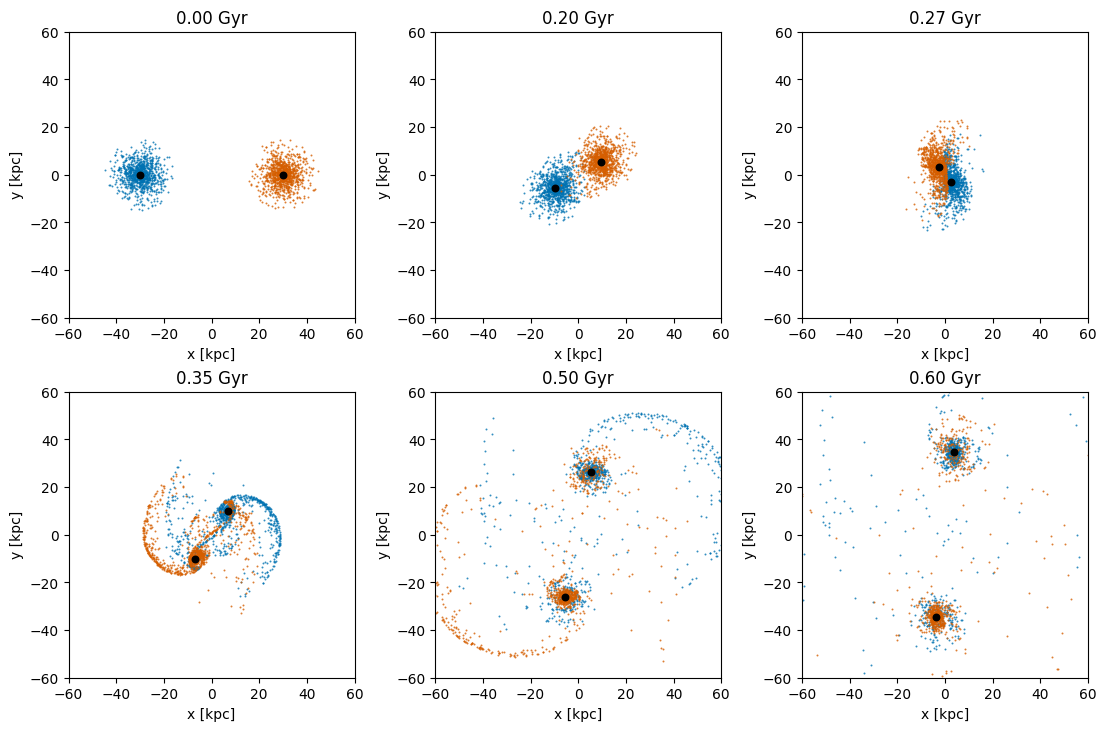

In [10]:
ncols = 3
nrows = int(np.ceil(len(SNAPSHOT_TIMES) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(11.0, 7.2), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, t in zip(axes, SNAPSHOT_TIMES):
    state = snapshots[t]
    disk1 = state[2:2 + N1]
    disk2 = state[2 + N1:]

    ax.scatter(disk1[:, 0], disk1[:, 1], s=2.0, c=BLUE, alpha=0.8, linewidths=0)
    ax.scatter(disk2[:, 0], disk2[:, 1], s=2.0, c=VERMILLION, alpha=0.8, linewidths=0)
    ax.scatter(state[:2, 0], state[:2, 1], s=22.0, c=BLACK, marker="o")

    ax.set_title(f"{t:.2f} Gyr")
    ax.set_xlabel("x [kpc]")
    ax.set_ylabel("y [kpc]")
    ax.set_xlim(-60.0, 60.0)
    ax.set_ylim(-60.0, 60.0)
    ax.set_aspect("equal")

for ax in axes[len(SNAPSHOT_TIMES):]:
    ax.axis("off")

plt.show()

## 10. 最近接距離と数値誤差を確認する

目標最近接距離は8 kpcです。また、RK4の時間刻みが十分小さければ、動力学的摩擦を含まない銀河中心軌道ではエネルギーと角運動量が高い精度で保存されます。

In [11]:
i_peri = np.argmin(separation)
e_scale = 0.5 * (G * (M1 + M2) / R0)
energy_error = np.max(np.abs(energy - energy[0])) / e_scale
angular_momentum_error = np.max(np.abs(angular_momentum - angular_momentum[0])) / abs(angular_momentum[0])

print(f"Minimum separation = {separation[i_peri]:.3f} kpc")
print(f"Pericenter time = {times[i_peri]:.3f} Gyr")
print(f"Max energy error = {energy_error:.3e} (normalized)")
print(f"Max angular-momentum error = {angular_momentum_error:.3e}")

Minimum separation = 8.000 kpc
Pericenter time = 0.270 Gyr
Max energy error = 2.591e-07 (normalized)
Max angular-momentum error = 1.871e-09


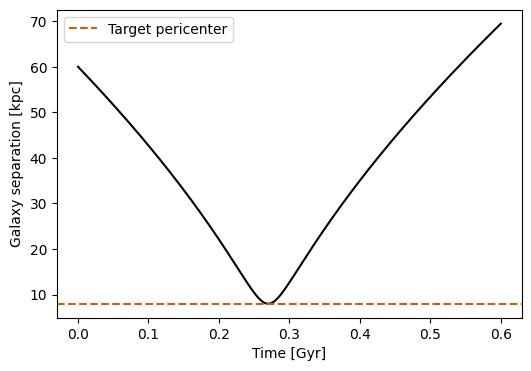

In [12]:
fig, ax = plt.subplots(figsize=(6.0, 4.0))
ax.plot(times, separation, c=BLACK)
ax.axhline(R_PERI, ls="--", c=VERMILLION, label="Target pericenter")
ax.set_xlabel("Time [Gyr]")
ax.set_ylabel("Galaxy separation [kpc]")
ax.legend()
plt.show()

## 11. 簡単な数値実験

次の変更を試して、結果がどう変わるか確認してください。

### 確認
`DT = 0.002`, `0.001`, `0.0005` Gyr と変えて、エネルギー誤差を比較してください。

### 応用
`R_PERI` を 5, 8, 12 kpc と変えて、潮汐構造の強さを比較してください。

### 発展
`SPIN_2 = -1` として、prograde--retrograde encounter を計算してください。prograde側とretrograde側で潮汐テイルの形にどのような違いが生じるか考えてください。

> **もう少し詳しく**  
> 本格的な重力N体計算ではleapfrog法などのsymplectic積分法がよく使われます。本書では一般的な常微分方程式に適用でき、後で速度依存のChandrasekhar動力学的摩擦も扱いやすいRK4を標準法とします。

## この最小モデルで無視しているもの

このNotebookは、銀河相互作用の基本的な物理を学ぶための簡略モデルです。

- テスト粒子同士の自己重力
- 円盤から銀河中心へのback reaction
- ガス力学
- 星形成とフィードバック
- ダークハローの自己無撞着な応答
- 3次元構造
- 動力学的摩擦

はまだ含めていません。

これらをすべて含めることが目的ではありません。まず、**単純なモデルで潮汐相互作用がどのように銀河の形を変えるかを理解する**ことを目標とします。